In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
file_path = "/content/covid_19_clean_complete.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 49068
Columns: 10


In [ ]:
print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of countries/regions:", df["Country/Region"].nunique())

print("\nColumns:")
print(df.columns.tolist())

Shape: (49068, 10)
Date range: 2020-01-22 to 2020-07-27
Number of countries/regions: 187

Columns:
['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'WHO Region']


In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64

Duplicate rows: 0


In [ ]:
df[["Confirmed", "Deaths", "Recovered", "Active"]].describe()

,Confirmed,Deaths,Recovered,Active
count,4.906800e+04,49068.000000,4.906800e+04,4.906800e+04
mean,1.688490e+04,884.179160,7.915713e+03,8.085012e+03
std,1.273002e+05,6313.584411,5.480092e+04,7.625890e+04
min,0.000000e+00,0.000000,0.000000e+00,-1.400000e+01
25%,4.000000e+00,0.000000,0.000000e+00,0.000000e+00
50%,1.680000e+02,2.000000,2.900000e+01,2.600000e+01
75%,1.518250e+03,30.000000,6.660000e+02,6.060000e+02
max,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06


In [ ]:
df = df.sort_values(
    ["Country/Region", "Date"]
).reset_index(drop=True)

In [ ]:
df["Daily_Cases"] = (
    df.groupby("Country/Region")["Confirmed"]
      .diff()
      .fillna(0)
)

df["Daily_Deaths"] = (
    df.groupby("Country/Region")["Deaths"]
      .diff()
      .fillna(0)
)

df["Daily_Recovered"] = (
    df.groupby("Country/Region")["Recovered"]
      .diff()
      .fillna(0)
)

In [ ]:
df[
    ["Country/Region", "Date", "Confirmed",
     "Daily_Cases", "Deaths", "Daily_Deaths"]
].head(20)

,Country/Region,Date,Confirmed,Daily_Cases,Deaths,Daily_Deaths
0,Afghanistan,2020-01-22,0,0.0,0,0.0
1,Afghanistan,2020-01-23,0,0.0,0,0.0
2,Afghanistan,2020-01-24,0,0.0,0,0.0
3,Afghanistan,2020-01-25,0,0.0,0,0.0
4,Afghanistan,2020-01-26,0,0.0,0,0.0
5,Afghanistan,2020-01-27,0,0.0,0,0.0
6,Afghanistan,2020-01-28,0,0.0,0,0.0
7,Afghanistan,2020-01-29,0,0.0,0,0.0
8,Afghanistan,2020-01-30,0,0.0,0,0.0
9,Afghanistan,2020-01-31,0,0.0,0,0.0


In [ ]:
print("Total daily case records:", len(df))
print("Maximum daily cases:", df["Daily_Cases"].max())
print("Minimum daily cases:", df["Daily_Cases"].min())

Total daily case records: 49068
Maximum daily cases: 300099.0
Minimum daily cases: -300108.0


In [ ]:
# Aggregate COVID data to country and date level

country_daily = (
    df.groupby(["Country/Region", "Date"], as_index=False)
      .agg({
          "Confirmed": "sum",
          "Deaths": "sum",
          "Recovered": "sum",
          "Active": "sum"
      })
)

# Sort correctly
country_daily = country_daily.sort_values(
    ["Country/Region", "Date"]
).reset_index(drop=True)

print("Country-date records:", len(country_daily))
country_daily.head()

Country-date records: 35156


,Country/Region,Date,Confirmed,Deaths,Recovered,Active
0,Afghanistan,2020-01-22,0,0,0,0
1,Afghanistan,2020-01-23,0,0,0,0
2,Afghanistan,2020-01-24,0,0,0,0
3,Afghanistan,2020-01-25,0,0,0,0
4,Afghanistan,2020-01-26,0,0,0,0


In [ ]:
country_daily["Daily_Cases"] = (
    country_daily.groupby("Country/Region")["Confirmed"]
    .diff()
    .fillna(0)
)

country_daily["Daily_Deaths"] = (
    country_daily.groupby("Country/Region")["Deaths"]
    .diff()
    .fillna(0)
)

country_daily["Daily_Recovered"] = (
    country_daily.groupby("Country/Region")["Recovered"]
    .diff()
    .fillna(0)
)

In [ ]:
print("Maximum daily cases:", country_daily["Daily_Cases"].max())
print("Minimum daily cases:", country_daily["Daily_Cases"].min())

print(
    "Negative daily case records:",
    (country_daily["Daily_Cases"] < 0).sum()
)

Maximum daily cases: 77255.0
Minimum daily cases: -10034.0
Negative daily case records: 33


In [ ]:
country_daily["Daily_Cases_Clean"] = country_daily["Daily_Cases"].clip(lower=0)

In [ ]:
country_daily["Daily_Deaths_Clean"] = country_daily["Daily_Deaths"].clip(lower=0)

In [ ]:
print("Negative cleaned daily cases:",
      (country_daily["Daily_Cases_Clean"] < 0).sum())

print("Negative cleaned daily deaths:",
      (country_daily["Daily_Deaths_Clean"] < 0).sum())

Negative cleaned daily cases: 0
Negative cleaned daily deaths: 0


In [ ]:
weekly_cases = (
    country_daily
    .set_index("Date")
    .groupby("Country/Region")["Daily_Cases_Clean"]
    .resample("W")
    .sum()
    .reset_index()
)

weekly_cases.rename(
    columns={"Daily_Cases_Clean": "Weekly_Cases"},
    inplace=True
)

print("Weekly records:", len(weekly_cases))
weekly_cases.head()

TypeError: Only valid with DatetimeIndex, TimedeltaIndex or PeriodIndex, but got an instance of 'Index'

In [ ]:
country_daily["Date"] = pd.to_datetime(country_daily["Date"])

In [ ]:
weekly_cases = (
    country_daily
    .set_index("Date")
    .groupby("Country/Region")["Daily_Cases_Clean"]
    .resample("W")
    .sum()
    .reset_index()
)

weekly_cases.rename(
    columns={"Daily_Cases_Clean": "Weekly_Cases"},
    inplace=True
)

print("Weekly records:", len(weekly_cases))
weekly_cases.head()

Weekly records: 5236


,Country/Region,Date,Weekly_Cases
0,Afghanistan,2020-01-26,0.0
1,Afghanistan,2020-02-02,0.0
2,Afghanistan,2020-02-09,0.0
3,Afghanistan,2020-02-16,0.0
4,Afghanistan,2020-02-23,0.0


In [ ]:
country_daily["Rolling_7Day_Cases"] = (
    country_daily
    .groupby("Country/Region")["Daily_Cases_Clean"]
    .transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )
)

print("7-day rolling average calculated successfully.")

7-day rolling average calculated successfully.


In [ ]:
country_totals = (
    country_daily
    .groupby("Country/Region")["Confirmed"]
    .max()
    .sort_values(ascending=False)
)

print("Top 10 countries by confirmed cases:")
print(country_totals.head(10))

Top 10 countries by confirmed cases:
Country/Region
US                4290259
Brazil            2442375
India             1480073
Russia             816680
South Africa       452529
Mexico             395489
Peru               389717
Chile              347923
United Kingdom     301708
Iran               293606
Name: Confirmed, dtype: int64


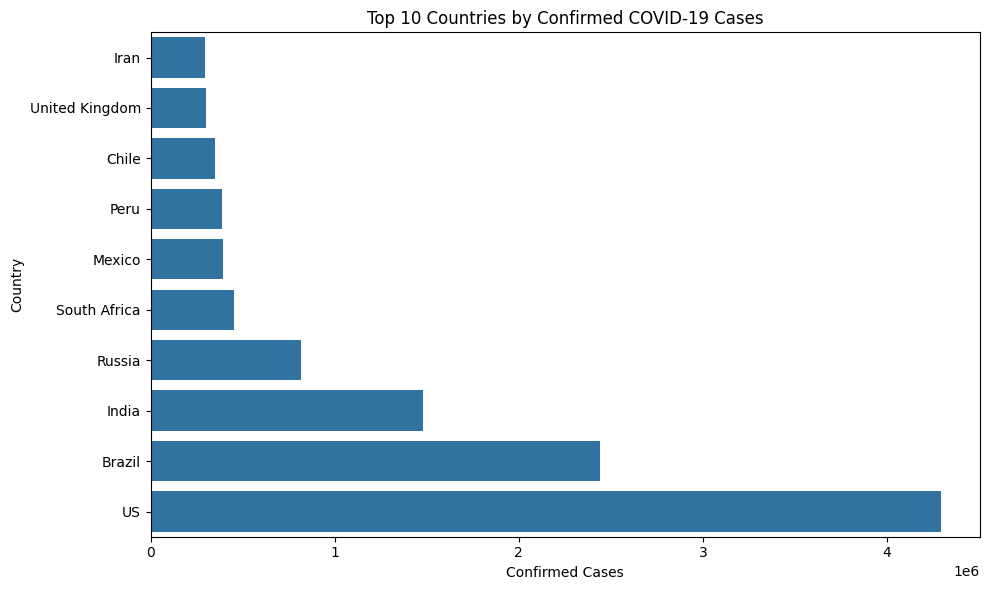

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10 = country_totals.head(10).sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10.values,
    y=top_10.index
)

plt.title("Top 10 Countries by Confirmed COVID-19 Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "top_10_countries_confirmed_cases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
plt.savefig(
    "top_10_countries_confirmed_cases.png",
    dpi=300,
    bbox_inches="tight"
)

print("Chart saved successfully.")

Chart saved successfully.


<Figure size 640x480 with 0 Axes>

Chart saved successfully.


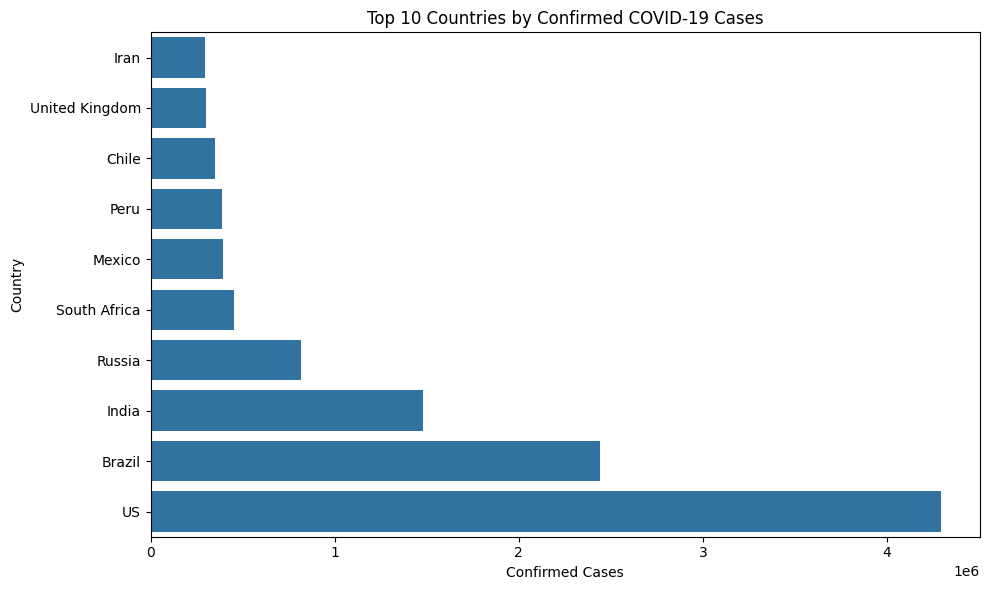

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10 = country_totals.head(10).sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10.values,
    y=top_10.index
)

plt.title("Top 10 Countries by Confirmed COVID-19 Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Country")

plt.tight_layout()

# Save BEFORE showing the chart
plt.savefig(
    "top_10_countries_confirmed_cases.png",
    dpi=300,
    bbox_inches="tight"
)

print("Chart saved successfully.")

plt.show()

In [ ]:
import os

file_path = "top_10_countries_confirmed_cases.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 103.78 KB


In [ ]:
selected_countries = [
    "US",
    "Brazil",
    "India",
    "Russia",
    "South Africa"
]

selected_daily = country_daily[
    country_daily["Country/Region"].isin(selected_countries)
].copy()

print("Selected countries:")
print(selected_daily["Country/Region"].unique())

Selected countries:
['Brazil' 'India' 'Russia' 'South Africa' 'US']


In [ ]:
print("Rows:", len(selected_daily))
print("Countries:", selected_daily["Country/Region"].nunique())
print(
    "Date range:",
    selected_daily["Date"].min(),
    "to",
    selected_daily["Date"].max()
)

Rows: 940
Countries: 5
Date range: 2020-01-22 00:00:00 to 2020-07-27 00:00:00


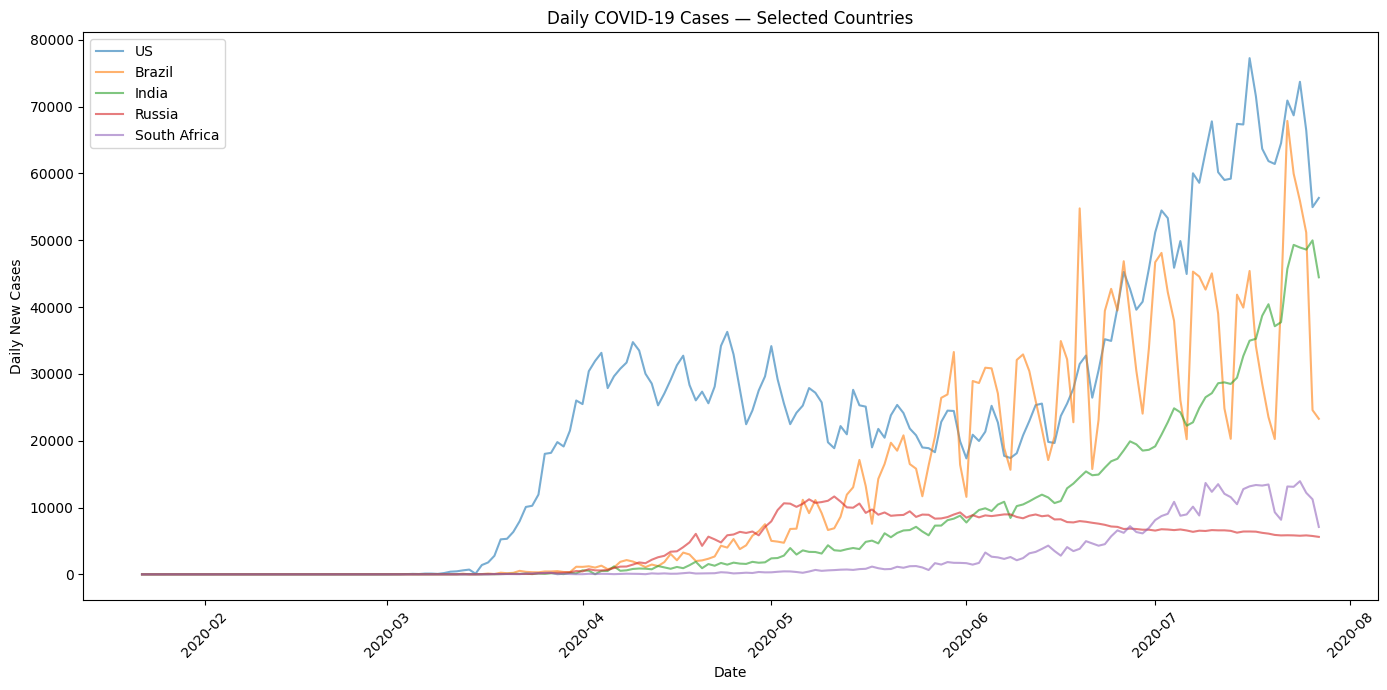

In [ ]:
plt.figure(figsize=(14, 7))

for country in selected_countries:
    country_data = selected_daily[
        selected_daily["Country/Region"] == country
    ]

    plt.plot(
        country_data["Date"],
        country_data["Daily_Cases_Clean"],
        label=country,
        alpha=0.6
    )

plt.title("Daily COVID-19 Cases — Selected Countries")
plt.xlabel("Date")
plt.ylabel("Daily New Cases")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "daily_cases_selected_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

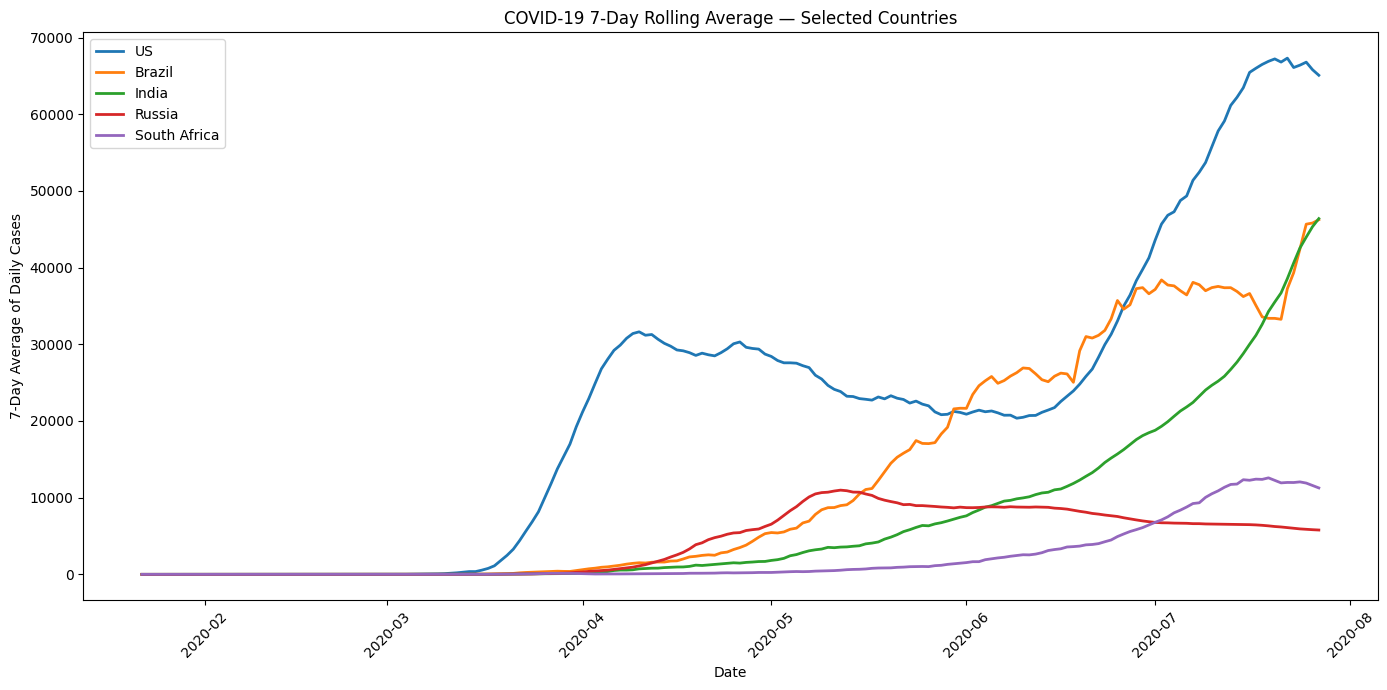

In [ ]:
plt.figure(figsize=(14, 7))

for country in selected_countries:
    country_data = selected_daily[
        selected_daily["Country/Region"] == country
    ]

    plt.plot(
        country_data["Date"],
        country_data["Rolling_7Day_Cases"],
        label=country,
        linewidth=2
    )

plt.title("COVID-19 7-Day Rolling Average — Selected Countries")
plt.xlabel("Date")
plt.ylabel("7-Day Average of Daily Cases")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "covid_7day_rolling_average_selected_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
peak_rolling = (
    selected_daily
    .loc[
        selected_daily.groupby("Country/Region")["Rolling_7Day_Cases"]
        .idxmax()
    ]
    [
        [
            "Country/Region",
            "Date",
            "Rolling_7Day_Cases"
        ]
    ]
    .sort_values("Rolling_7Day_Cases", ascending=False)
)

print(peak_rolling.to_string(index=False))

Country/Region       Date  Rolling_7Day_Cases
            US 2020-07-22        67317.000000
         India 2020-07-27        46390.714286
        Brazil 2020-07-27        46247.000000
  South Africa 2020-07-19        12583.714286
        Russia 2020-05-12        10981.857143


In [ ]:
peak_rolling.to_csv(
    "covid_peak_7day_rolling_average.csv",
    index=False
)

print("Peak analysis saved successfully.")

Peak analysis saved successfully.


In [ ]:
import os

file_path = "covid_peak_7day_rolling_average.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 0.2 KB


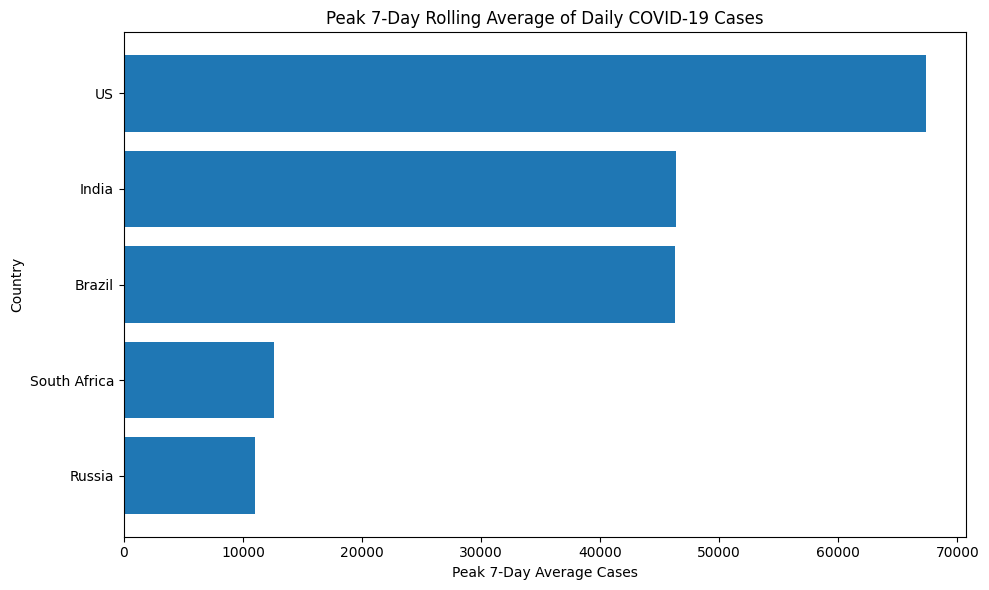

In [ ]:
plt.figure(figsize=(10, 6))

peak_plot = peak_rolling.sort_values("Rolling_7Day_Cases")

plt.barh(
    peak_plot["Country/Region"],
    peak_plot["Rolling_7Day_Cases"]
)

plt.title("Peak 7-Day Rolling Average of Daily COVID-19 Cases")
plt.xlabel("Peak 7-Day Average Cases")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "covid_peak_7day_rolling_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os

file_path = "covid_peak_7day_rolling_average.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 97.35 KB


In [ ]:
weekly_cases = (
    country_daily
    .set_index("Date")
    .groupby("Country/Region")["Daily_Cases_Clean"]
    .resample("W")
    .sum()
    .reset_index(name="Weekly_Cases")
)

print("Weekly records:", len(weekly_cases))
print(weekly_cases.head())

Weekly records: 5236
  Country/Region       Date  Weekly_Cases
0    Afghanistan 2020-01-26           0.0
1    Afghanistan 2020-02-02           0.0
2    Afghanistan 2020-02-09           0.0
3    Afghanistan 2020-02-16           0.0
4    Afghanistan 2020-02-23           0.0


In [ ]:
weekly_selected = weekly_cases[
    weekly_cases["Country/Region"].isin(selected_countries)
].copy()

print("Weekly records for selected countries:", len(weekly_selected))
print(
    "Countries:",
    weekly_selected["Country/Region"].nunique()
)

Weekly records for selected countries: 140
Countries: 5


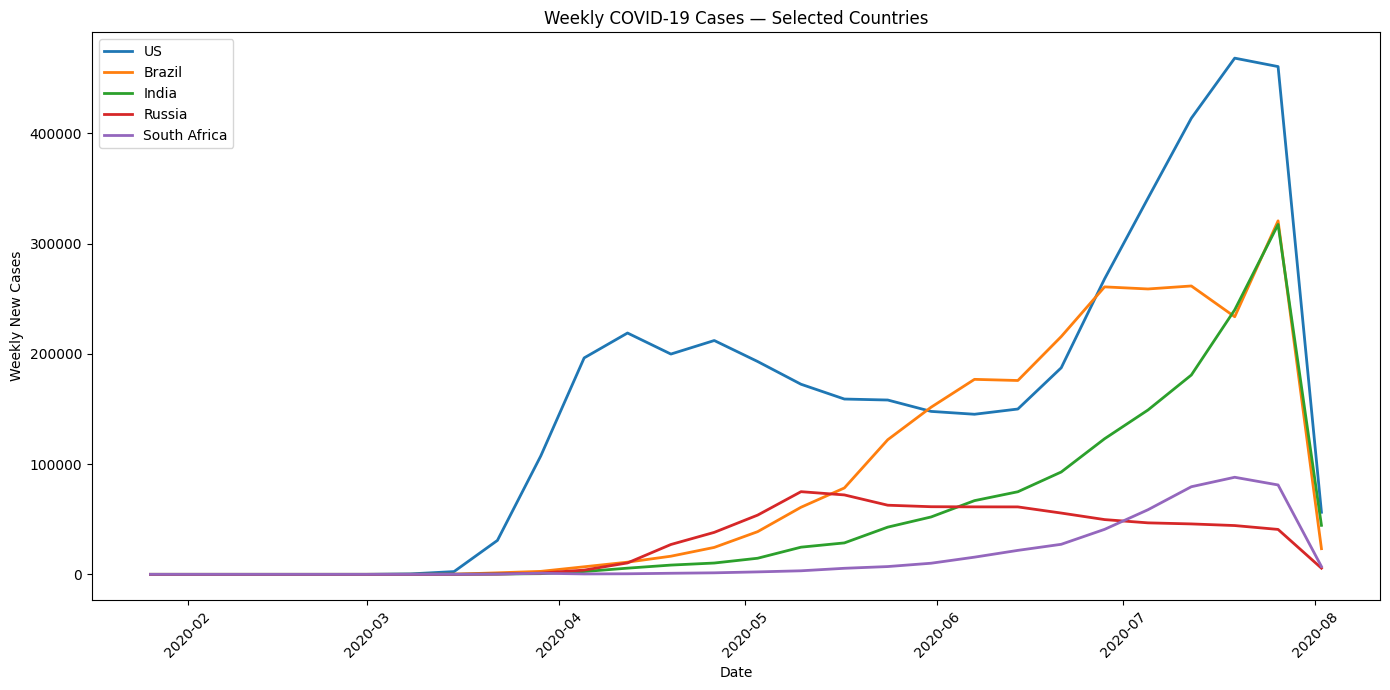

In [ ]:
plt.figure(figsize=(14, 7))

for country in selected_countries:
    country_data = weekly_selected[
        weekly_selected["Country/Region"] == country
    ]

    plt.plot(
        country_data["Date"],
        country_data["Weekly_Cases"],
        label=country,
        linewidth=2
    )

plt.title("Weekly COVID-19 Cases — Selected Countries")
plt.xlabel("Date")
plt.ylabel("Weekly New Cases")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "weekly_covid_cases_selected_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os

file_path = "weekly_covid_cases_selected_countries.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 320.35 KB


In [ ]:
weekly_peaks = (
    weekly_selected
    .loc[
        weekly_selected.groupby("Country/Region")["Weekly_Cases"]
        .idxmax()
    ]
    [
        [
            "Country/Region",
            "Date",
            "Weekly_Cases"
        ]
    ]
    .sort_values("Weekly_Cases", ascending=False)
)

print(weekly_peaks.to_string(index=False))

Country/Region       Date  Weekly_Cases
            US 2020-07-19      468318.0
        Brazil 2020-07-26      320702.0
         India 2020-07-26      317410.0
  South Africa 2020-07-19       88086.0
        Russia 2020-05-10       75001.0


In [ ]:
weekly_peaks.to_csv(
    "covid_peak_weekly_cases.csv",
    index=False
)

print("Weekly peak analysis saved successfully.")

Weekly peak analysis saved successfully.


In [ ]:
import os

file_path = "covid_peak_weekly_cases.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 0.16 KB


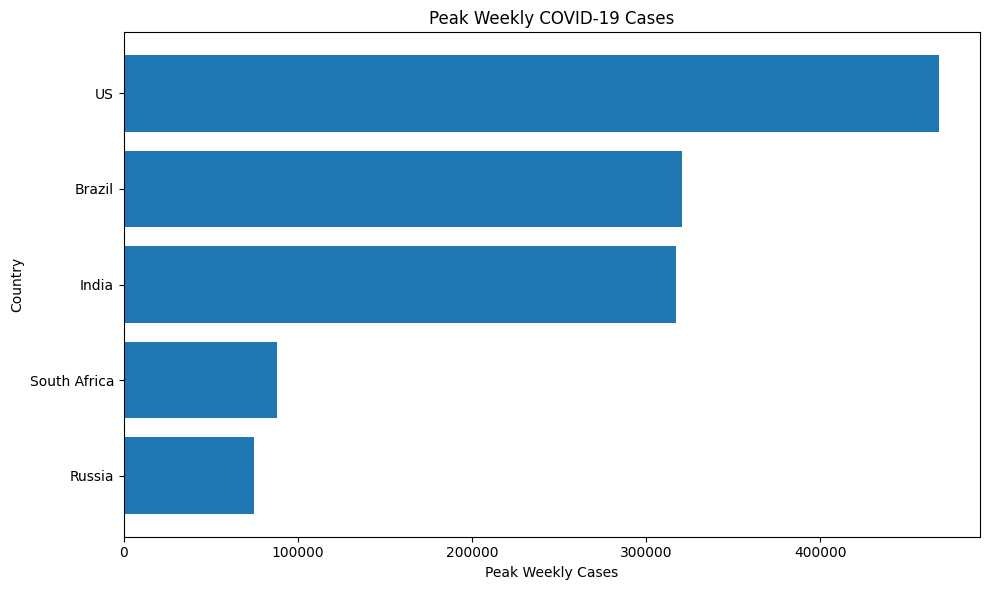

In [ ]:
plt.figure(figsize=(10, 6))

weekly_peak_plot = weekly_peaks.sort_values("Weekly_Cases")

plt.barh(
    weekly_peak_plot["Country/Region"],
    weekly_peak_plot["Weekly_Cases"]
)

plt.title("Peak Weekly COVID-19 Cases")
plt.xlabel("Peak Weekly Cases")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "covid_peak_weekly_cases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os

file_path = "covid_peak_weekly_cases.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 83.79 KB


In [ ]:
weekly_growth = weekly_selected.copy()

weekly_growth["Weekly_Growth_%"] = (
    weekly_growth
    .groupby("Country/Region")["Weekly_Cases"]
    .pct_change()
    .replace([np.inf, -np.inf], np.nan)
    * 100
)

print(
    weekly_growth[
        [
            "Country/Region",
            "Date",
            "Weekly_Cases",
            "Weekly_Growth_%"
        ]
    ].tail(15).to_string(index=False)
)

Country/Region       Date  Weekly_Cases  Weekly_Growth_%
            US 2020-04-26      212143.0         6.149520
            US 2020-05-03      193093.0        -8.979792
            US 2020-05-10      172473.0       -10.678792
            US 2020-05-17      159048.0        -7.783827
            US 2020-05-24      158157.0        -0.560208
            US 2020-05-31      147835.0        -6.526426
            US 2020-06-07      145246.0        -1.751277
            US 2020-06-14      149996.0         3.270314
            US 2020-06-21      187401.0        24.937332
            US 2020-06-28      268097.0        43.060603
            US 2020-07-05      341260.0        27.289750
            US 2020-07-12      413818.0        21.261795
            US 2020-07-19      468318.0        13.170041
            US 2020-07-26      460663.0        -1.634573
            US 2020-08-02       56336.0       -87.770670


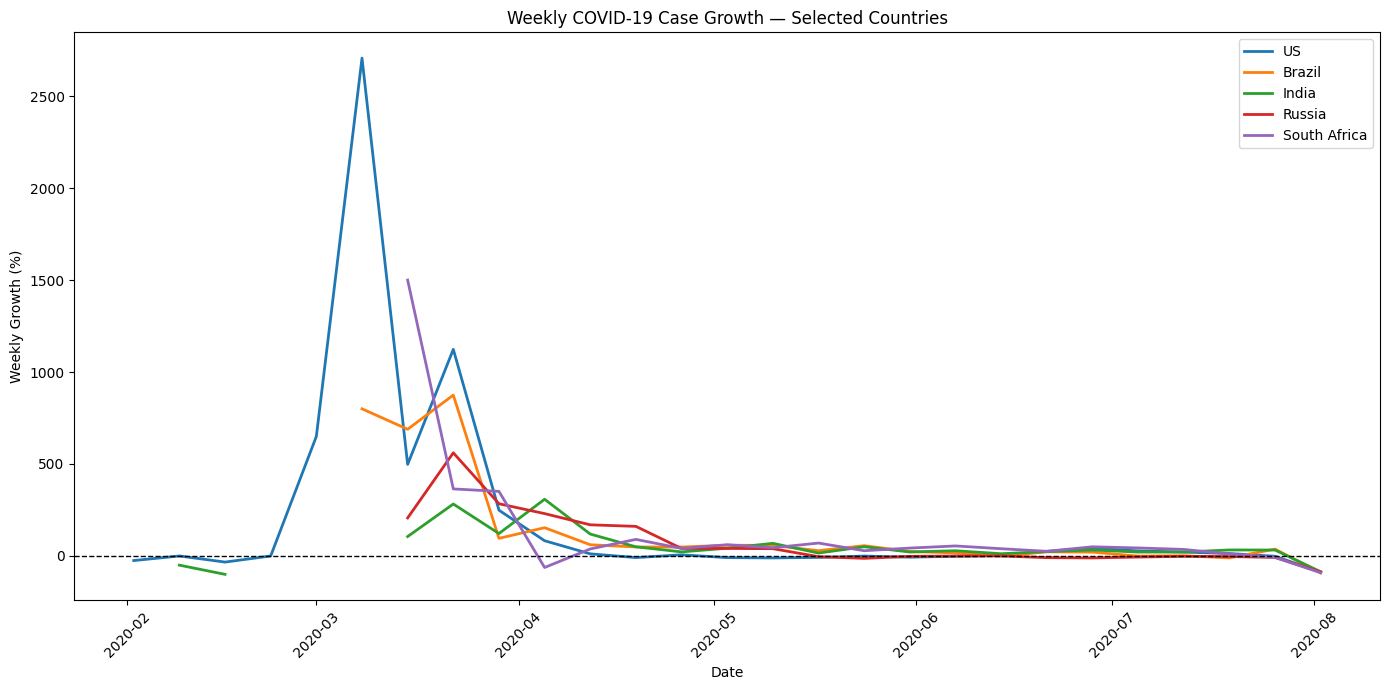

In [ ]:
plt.figure(figsize=(14, 7))

for country in selected_countries:
    country_data = weekly_growth[
        weekly_growth["Country/Region"] == country
    ]

    plt.plot(
        country_data["Date"],
        country_data["Weekly_Growth_%"],
        label=country,
        linewidth=2
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Weekly COVID-19 Case Growth — Selected Countries")
plt.xlabel("Date")
plt.ylabel("Weekly Growth (%)")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "weekly_covid_case_growth_selected_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
import os

file_path = "weekly_covid_case_growth_selected_countries.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 281.31 KB


In [46]:
late_growth = weekly_growth[
    (weekly_growth["Date"] >= "2020-06-01") &
    (weekly_growth["Date"] <= "2020-07-27")
].copy()

growth_summary = (
    late_growth
    .groupby("Country/Region")["Weekly_Growth_%"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

growth_summary.columns = [
    "Country/Region",
    "Average_Weekly_Growth_%"
]

print(growth_summary.to_string(index=False))

Country/Region  Average_Weekly_Growth_%
  South Africa                31.381780
         India                25.541846
            US                16.200498
        Brazil                10.813959
        Russia                -4.906958


In [47]:
growth_summary.to_csv(
    "covid_weekly_growth_summary.csv",
    index=False
)

print("Weekly growth summary saved successfully.")

Weekly growth summary saved successfully.


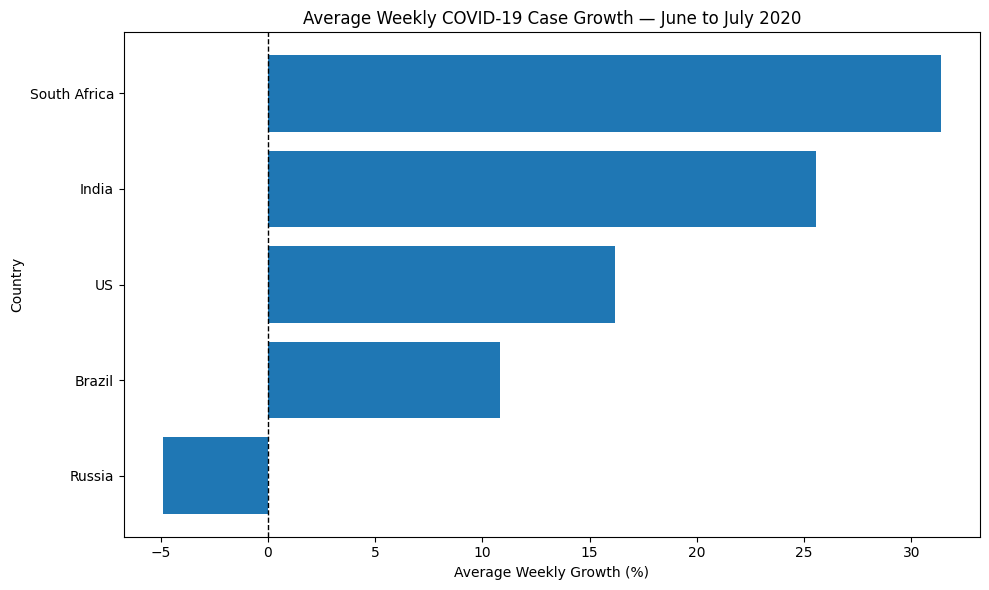

In [48]:
plt.figure(figsize=(10, 6))

growth_plot = growth_summary.sort_values(
    "Average_Weekly_Growth_%"
)

plt.barh(
    growth_plot["Country/Region"],
    growth_plot["Average_Weekly_Growth_%"]
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Average Weekly COVID-19 Case Growth — June to July 2020")
plt.xlabel("Average Weekly Growth (%)")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "covid_weekly_growth_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
import os

file_path = "covid_weekly_growth_summary.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 104.85 KB


In [50]:
final_date = country_daily["Date"].max()

final_cases = (
    country_daily[
        (country_daily["Date"] == final_date) &
        (country_daily["Country/Region"].isin(selected_countries))
    ][
        ["Country/Region", "Confirmed"]
    ]
    .sort_values("Confirmed", ascending=False)
)

print("Final date:", final_date)
print(final_cases.to_string(index=False))

Final date: 2020-07-27 00:00:00
Country/Region  Confirmed
            US    4290259
        Brazil    2442375
         India    1480073
        Russia     816680
  South Africa     452529


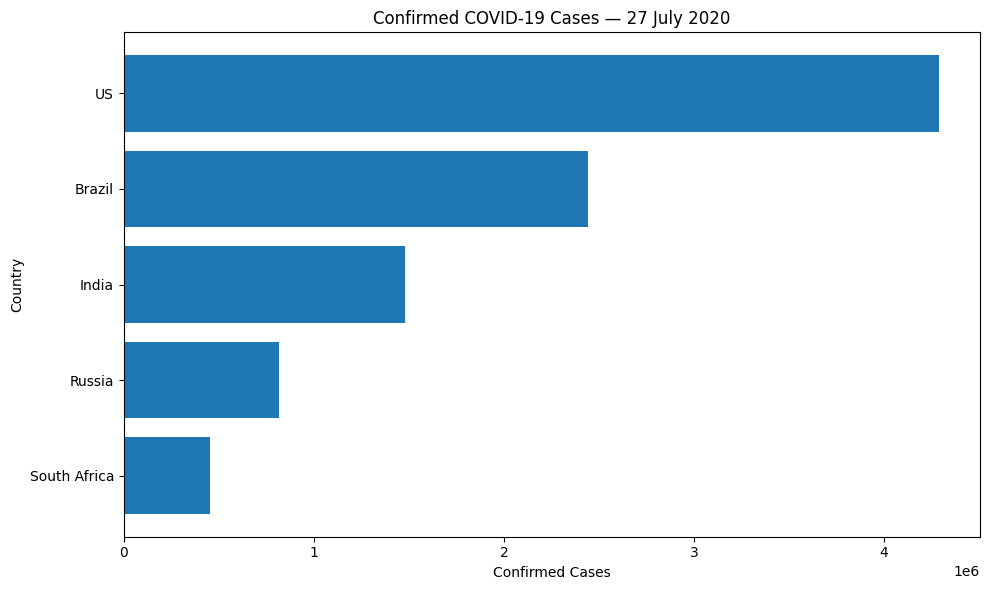

In [51]:
plt.figure(figsize=(10, 6))

final_plot = final_cases.sort_values("Confirmed")

plt.barh(
    final_plot["Country/Region"],
    final_plot["Confirmed"]
)

plt.title("Confirmed COVID-19 Cases — 27 July 2020")
plt.xlabel("Confirmed Cases")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "final_confirmed_cases_selected_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
import os

file_path = "final_confirmed_cases_selected_countries.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 84.13 KB


In [53]:
final_summary = pd.DataFrame({
    "Country/Region": selected_countries
})

final_summary = final_summary.merge(
    final_cases,
    on="Country/Region",
    how="left"
)

final_summary = final_summary.merge(
    weekly_peaks[
        ["Country/Region", "Date", "Weekly_Cases"]
    ].rename(
        columns={
            "Date": "Peak_Weekly_Date",
            "Weekly_Cases": "Peak_Weekly_Cases"
        }
    ),
    on="Country/Region",
    how="left"
)

final_summary = final_summary.merge(
    peak_rolling[
        ["Country/Region", "Date", "Rolling_7Day_Cases"]
    ].rename(
        columns={
            "Date": "Peak_Rolling_Date",
            "Rolling_7Day_Cases": "Peak_7Day_Average"
        }
    ),
    on="Country/Region",
    how="left"
)

final_summary = final_summary.merge(
    growth_summary,
    on="Country/Region",
    how="left"
)

print(final_summary.to_string(index=False))

Country/Region  Confirmed Peak_Weekly_Date  Peak_Weekly_Cases Peak_Rolling_Date  Peak_7Day_Average  Average_Weekly_Growth_%
            US    4290259       2020-07-19           468318.0        2020-07-22       67317.000000                16.200498
        Brazil    2442375       2020-07-26           320702.0        2020-07-27       46247.000000                10.813959
         India    1480073       2020-07-26           317410.0        2020-07-27       46390.714286                25.541846
        Russia     816680       2020-05-10            75001.0        2020-05-12       10981.857143                -4.906958
  South Africa     452529       2020-07-19            88086.0        2020-07-19       12583.714286                31.381780


In [54]:
final_summary.to_csv(
    "covid_final_analysis_summary.csv",
    index=False
)

print("Final COVID-19 analysis summary saved successfully.")

Final COVID-19 analysis summary saved successfully.


In [55]:
import os

file_path = "covid_final_analysis_summary.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 0.5 KB


In [56]:
conclusions = """
COVID-19 Data Analysis — Brief Conclusions

1. The United States had the highest confirmed case count among the selected countries by 27 July 2020.

2. The United States also recorded the highest peak weekly cases and highest peak 7-day rolling average among the five selected countries.

3. India and Brazil showed substantial increases in weekly cases during June and July 2020.

4. South Africa had the highest average weekly case growth during the June–July period among the selected countries.

5. Russia showed negative average weekly growth during the selected June–July period, indicating a declining weekly case trend in this analysis.

6. The 7-day rolling average helped smooth daily fluctuations and made overall case trends easier to compare.

7. Weekly aggregation reduced daily reporting noise and provided a clearer view of major changes in case activity.

Note:
The weekly growth comparison is a descriptive growth analysis and should not be interpreted as a formal epidemiological reproduction number (R0 or Rt).
"""

with open("covid_analysis_conclusions.txt", "w", encoding="utf-8") as file:
    file.write(conclusions)

print("Conclusions file created successfully.")

Conclusions file created successfully.


In [57]:
import os

file_path = "covid_analysis_conclusions.txt"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print(
        "File size:",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

File exists: True
File size: 1.01 KB


In [58]:
import os

output_files = [
    "daily_cases_selected_countries.png",
    "covid_7day_rolling_average_selected_countries.png",
    "covid_peak_7day_rolling_average.csv",
    "covid_peak_7day_rolling_average.png",
    "weekly_covid_cases_selected_countries.png",
    "covid_peak_weekly_cases.csv",
    "covid_peak_weekly_cases.png",
    "weekly_covid_case_growth_selected_countries.png",
    "covid_weekly_growth_summary.csv",
    "covid_weekly_growth_summary.png",
    "final_confirmed_cases_selected_countries.png",
    "covid_final_analysis_summary.csv",
    "covid_analysis_conclusions.txt"
]

for file in output_files:
    print(
        "✓" if os.path.exists(file) else "✗",
        file
    )

✓ daily_cases_selected_countries.png
✓ covid_7day_rolling_average_selected_countries.png
✓ covid_peak_7day_rolling_average.csv
✓ covid_peak_7day_rolling_average.png
✓ weekly_covid_cases_selected_countries.png
✓ covid_peak_weekly_cases.csv
✓ covid_peak_weekly_cases.png
✓ weekly_covid_case_growth_selected_countries.png
✓ covid_weekly_growth_summary.csv
✓ covid_weekly_growth_summary.png
✓ final_confirmed_cases_selected_countries.png
✓ covid_final_analysis_summary.csv
✓ covid_analysis_conclusions.txt


In [59]:
import os
import shutil

output_folder = "COVID-19_Project_Outputs"

os.makedirs(output_folder, exist_ok=True)

for file in output_files:
    if os.path.exists(file):
        shutil.copy2(file, output_folder)

print("Output folder created:", os.path.exists(output_folder))
print("Files copied:", len(os.listdir(output_folder)))

Output folder created: True
Files copied: 13


In [60]:
print("COVID-19 PROJECT OUTPUTS")
print("=" * 50)

for file in sorted(os.listdir("COVID-19_Project_Outputs")):
    print(file)

print("=" * 50)
print(
    "Total files:",
    len(os.listdir("COVID-19_Project_Outputs"))
)

COVID-19 PROJECT OUTPUTS
covid_7day_rolling_average_selected_countries.png
covid_analysis_conclusions.txt
covid_final_analysis_summary.csv
covid_peak_7day_rolling_average.csv
covid_peak_7day_rolling_average.png
covid_peak_weekly_cases.csv
covid_peak_weekly_cases.png
covid_weekly_growth_summary.csv
covid_weekly_growth_summary.png
daily_cases_selected_countries.png
final_confirmed_cases_selected_countries.png
weekly_covid_case_growth_selected_countries.png
weekly_covid_cases_selected_countries.png
Total files: 13


In [61]:
import shutil

zip_path = shutil.make_archive(
    "COVID-19_Project_Outputs",
    "zip",
    "COVID-19_Project_Outputs"
)

print("ZIP created successfully:", zip_path)

ZIP created successfully: /content/COVID-19_Project_Outputs.zip


In [62]:
from google.colab import files

files.download("/content/COVID-19_Project_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>